[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JPEDROPS092/machine-learning-algorithms/blob/main/notebooks/11-comparando-logistic-regression-e-naive-bayes.ipynb)

# Naive Bayes e regressao logistica no mesmo filtro de spam

Os dois modelos leem o SMS Spam Collection da UCI (conjunto 228), o mesmo arquivo do primeiro caderno, com o mesmo recorte: 25% de teste, semente 0, estratificado. A classe positiva e spam.

O Naive Bayes multinomial olha contagens e, numa segunda passagem, TF-IDF. A regressao logistica olha o TF-IDF, porque o escore linear se da melhor com linhas de norma parecida. Os dois do zero sao comparados ao scikit-learn na mesma matriz.


In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q numpy pandas scikit-learn matplotlib seaborn requests
    import os
    if not os.path.isdir("/content/ml-algoritmos/src/mlalgos"):
        !git clone --depth 1 https://github.com/JPEDROPS092/machine-learning-algorithms.git /content/ml-algoritmos
    if "/content/ml-algoritmos/src" not in sys.path:
        sys.path.insert(0, "/content/ml-algoritmos/src")
    PASTA_DADOS = Path("/content/data")
else:
    aqui = Path.cwd().resolve()
    raiz = aqui if (aqui / "src" / "mlalgos").exists() else aqui.parent
    if not (raiz / "src" / "mlalgos").exists():
        raise RuntimeError(
            "Nao encontrei src/mlalgos. Abra o notebook na pasta notebooks ou na raiz do repositorio."
        )
    if str(raiz / "src") not in sys.path:
        sys.path.insert(0, str(raiz / "src"))
    PASTA_DADOS = raiz / "data"

PASTA_DADOS.mkdir(parents=True, exist_ok=True)

%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def baixar(url, destino):
    """Baixa um arquivo so se ele ainda nao estiver na pasta data, que nao entra no git."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    import requests

    resposta = requests.get(url, timeout=180, headers={"User-Agent": "ml-algoritmos-aula/1.0"})
    resposta.raise_for_status()
    destino.write_bytes(resposta.content)
    return destino


def padronizar(treino, teste):
    """Z-score com media e desvio do treino. O teste usa os mesmos numeros, sem vazar."""
    treino = np.asarray(treino, dtype=float)
    teste = np.asarray(teste, dtype=float)
    media = treino.mean(axis=0)
    desvio = treino.std(axis=0)
    desvio = np.where(desvio == 0, 1.0, desvio)
    return (treino - media) / desvio, (teste - media) / desvio, media, desvio


## 1) Intuição

Os dois algoritmos podem barrar a mesma mensagem e mesmo assim "pensar" diferente. O Naive Bayes pergunta: se isto fosse spam, cada palavra seria comum? E multiplica. A regressao logistica pergunta: a soma dos pesos destas palavras cruzou a cerca? Um erra quando as palavras nao sao independentes. O outro erra quando a cerca reta nao basta, ou quando o passo nao chegou no minimo.

No spam curto os dois costumam ficar perto, porque muitas palavras de propaganda sao quase exclusivas. A diferenca aparece no tipo de erro e na calibragem da probabilidade, nao so na acuracia.


## 2) Fundamentação matemática

O teorema de Bayes inverte a pergunta. Em vez de perguntar so quao tipico e o texto dentro de uma classe, calculamos a chance da classe depois de ler o texto:

$$
P(y \mid x) = \frac{P(x \mid y)\, P(y)}{P(x)}
$$

- $P(y \mid x)$ e a probabilidade da classe $y$ depois de observar $x$. E a saida do classificador.
- $P(x \mid y)$ e a verossimilhanca: a chance de ver esse texto se a classe for $y$.
- $P(y)$ e o prior, a frequencia da classe antes de olhar o texto.
- $P(x)$ e a evidencia. Ela nao depende de $y$, entao nao muda qual classe ganha. Na hora de decidir, comparamos $P(x \mid y)\,P(y)$.

A hipotese de independencia condicional, a parte ingênua do nome, diz que, dada a classe, uma palavra nao informa a outra:

$$
P(x \mid y) = \prod_{j=1}^{d} P(x_j \mid y)
$$

- $x_j$ e a contagem da palavra $j$.
- $d$ e o tamanho do vocabulario.
- O produto e falso em frases reais ("nao" muda "bom"), mas o erro muitas vezes se reparte e o sinal de cada palavra ainda aponta a classe certa.

No modelo multinomial a probabilidade de uma palavra e a fatia dela nas contagens da classe. A suavizacao de Laplace soma $\alpha$ para uma palavra nunca vista nao zerar o produto inteiro:

$$
\hat{P}(w \mid y) = \frac{n_{y,w} + \alpha}{n_y + \alpha \, |V|}
$$

- $n_{y,w}$ e quantas vezes a palavra $w$ apareceu na classe $y$.
- $n_y$ e a soma de todas as contagens da classe.
- $|V|$ e o numero de palavras do vocabulario.
- $\alpha$ e a forca da suavizacao. Com $\alpha = 1$ ha uma ocorrencia ficticia de cada palavra em cada classe.

Mil probabilidades pequenas, multiplicadas, estouram para zero no computador. O logaritmo transforma o produto em soma:

$$
\log P(y \mid x) \propto \log P(y) + \sum_{j=1}^{d} x_j \, \log \hat{P}(w_j \mid y)
$$

- $\log P(y)$ e o prior em escala de log.
- $x_j \log \hat{P}(w_j \mid y)$ pesa a palavra pela contagem dela neste texto. Palavra ausente entra com zero.
- A classe escolhida e a de maior soma. Para converter as somas em probabilidades que somam 1, subtraimos o log-sum-exp de todas as classes.


A regressao logistica desenha um escore linear e o espreme numa probabilidade. O escore e

$$
z = w^{\top} x + b
$$

- $x$ e o vetor de atributos da amostra.
- $w$ e o vetor de pesos, um por atributo.
- $b$ e o vies, o escore quando todos os atributos valem zero.
- $z$ e o logaritmo da chance, o log-odds: $\log \frac{p}{1-p} = z$.

A sigmoide converte $z$ na probabilidade da classe positiva:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

- Se $z = 0$, $\sigma(z) = 0{,}5$.
- Se $z$ cresce, $\sigma(z)$ sobe em direcao a 1, sem nunca passar de 1.
- Se $z$ cai, $\sigma(z)$ desce em direcao a 0.
- A derivada $\sigma(z)\,(1-\sigma(z))$ e a que aparece no gradiente.

Com mais de duas classes, cada classe tem seu escore $z_k$ e a softmax divide as exponenciais:

$$
P(y = k \mid x) = \frac{e^{z_k}}{\sum_{c=1}^{K} e^{z_c}}
$$

- $z_k = w_k^{\top} x + b_k$ e o escore da classe $k$.
- $K$ e o numero de classes.
- O denominador faz as $K$ probabilidades somarem 1.
- Subtrair $\max_c z_c$ antes da exponencial nao muda o resultado e evita estouro numerico.

O treino minimiza a entropia cruzada, a surpresa media de ter previsto pouco a classe verdadeira, mais uma penalidade L2 so nos pesos:

$$
J(w, b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\Big] + \frac{\lambda}{2}\|w\|^2
$$

- $n$ e o numero de amostras de treino.
- $y_i$ vale 1 na classe positiva e 0 na negativa.
- $\hat{p}_i = \sigma(w^{\top} x_i + b)$.
- $\lambda$ e o argumento `l2` do codigo. O vies $b$ nao entra em $\|w\|^2$: deslocar a fronteira nao deve ser punido do mesmo jeito que um peso enorme.
- No caso multiclasse, $y_i \log \hat{p}_i$ vira o log da probabilidade da classe correta.

A descida de gradiente anda no sentido em que $J$ diminui. Para a perda media acima, com a classe positiva codificada como 1:

$$
\frac{\partial J}{\partial w} = \frac{1}{n} X^{\top}(\hat{p} - y) + \lambda w, \qquad \frac{\partial J}{\partial b} = \frac{1}{n}\sum_{i=1}^{n}(\hat{p}_i - y_i)
$$

- $\hat{p} - y$ e o erro de cada amostra. Positivo quando o modelo exagerou a classe 1.
- $X^{\top}(\hat{p}-y)/n$ aponta quais atributos empurraram esse erro.
- $\lambda w$ encolhe os pesos em direcao a zero.
- O passo e $w \leftarrow w - \eta \, \partial J/\partial w$, e $\eta$ e o `learning_rate`.

O `C` do scikit-learn penaliza a soma dos erros, nao a media. Com $C = 1$, o $\lambda$ equivalente nesta media e $1/n$. E o valor usado nos cadernos para a comparacao ser justa. O otimizador deles (lbfgs) nao e o nosso passo fixo, entao os pesos nao precisam coincidir casa decimal; a qualidade no teste e que precisa ficar perto.

No Bayes, o peso de uma palavra e $\log \hat P(w \mid y)$, estimado por contagem, separado por classe. Na regressao logistica, o peso e livre: a descida de gradiente mexe nele para reduzir a entropia cruzada, e duas palavras podem dividir o credito de um jeito que a contagem bruta nao faria. O prior do Bayes e $\log P(y)$. O vies da logistica faz um papel parecido, mas nao e estimado como frequencia: ele entra no mesmo gradiente.


## 3) Visualização

O equilibrio das classes explica o resto do caderno: spam e minoria, e um modelo com AUC alta ainda pode ter F1 baixo se a probabilidade nao passa de 0,5.


mensagens 5574 spam 747 fonte: UCI 228


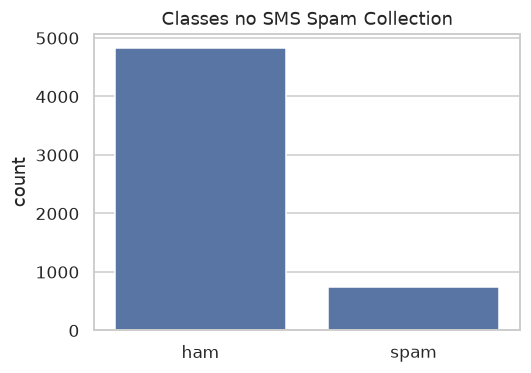

In [2]:
import zipfile

from sklearn.model_selection import train_test_split

arquivo = baixar(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip",
    PASTA_DADOS / "smsspamcollection.zip",
)
with zipfile.ZipFile(arquivo) as pacote:
    texto = pacote.read("SMSSpamCollection").decode("utf-8", errors="replace")
mensagens, ys = [], []
for linha in texto.splitlines():
    if "\t" not in linha:
        continue
    rotulo, mensagem = linha.split("\t", 1)
    mensagens.append(mensagem)
    ys.append(1 if rotulo == "spam" else 0)
y = np.array(ys)
print("mensagens", len(y), "spam", int(y.sum()), "fonte: UCI 228")
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x=np.where(y == 1, "spam", "ham"), ax=ax, color="#4c72b0")
ax.set_title("Classes no SMS Spam Collection")
ax.set_xlabel("")
plt.show()

X_treino_txt, X_teste_txt, y_treino, y_teste = train_test_split(
    mensagens, y, test_size=0.25, random_state=0, stratify=y,
)


## 4) Implementação do zero

Tres ajustes nossos: Bayes nas contagens, Bayes no TF-IDF e logistica no TF-IDF. A logistica usa passo 12 e 400 iteracoes. No TF-IDF a linha ja tem norma 1, e o passo precisa ser maior do que o dos atributos padronizados dos outros cadernos para a probabilidade de spam cruzar 0,5. A curva da perda mostra se o passo divergiu.


perda da logistica 0.6931 -> 0.1689


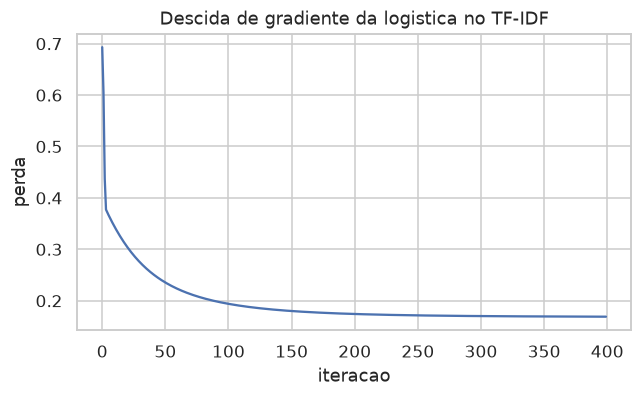

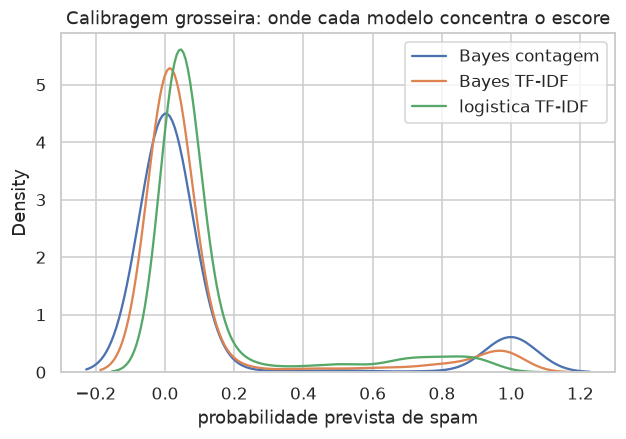

In [3]:
from mlalgos import BagOfWords, LogisticRegression, MultinomialNB, TfidfVectorizer

contagem = BagOfWords()
C_tr = contagem.fit_transform(X_treino_txt)
C_te = contagem.transform(X_teste_txt)
nb_contagem = MultinomialNB(alpha=1.0).fit(C_tr, y_treino)

tfidf = TfidfVectorizer(max_features=4000)
T_tr = tfidf.fit_transform(X_treino_txt)
T_te = tfidf.transform(X_teste_txt)
nb_tfidf = MultinomialNB(alpha=1.0).fit(T_tr, y_treino)

l2 = 1.0 / len(T_tr)
logistica = LogisticRegression(learning_rate=12.0, n_iterations=400, l2=l2).fit(T_tr, y_treino)
print("perda da logistica", round(logistica.loss_history_[0], 4), "->", round(logistica.loss_history_[-1], 4))
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(logistica.loss_history_)
ax.set_xlabel("iteracao")
ax.set_ylabel("perda")
ax.set_title("Descida de gradiente da logistica no TF-IDF")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))
for nome, escore in [
    ("Bayes contagem", nb_contagem.predict_proba(C_te)[:, 1]),
    ("Bayes TF-IDF", nb_tfidf.predict_proba(T_te)[:, 1]),
    ("logistica TF-IDF", logistica.predict_proba(T_te)[:, 1]),
]:
    sns.kdeplot(x=escore, ax=ax, label=nome, warn_singular=False)
ax.set_xlabel("probabilidade prevista de spam")
ax.set_title("Calibragem grosseira: onde cada modelo concentra o escore")
ax.legend()
plt.show()


## 5) Implementação com scikit-learn

Bayes na mesma matriz de contagens, e logistica do scikit-learn na mesma matriz TF-IDF com `C=1`.


In [4]:
from sklearn.linear_model import LogisticRegression as SkLogistic
from sklearn.naive_bayes import MultinomialNB as SkNB

sk_nb = SkNB(alpha=1.0).fit(C_tr, y_treino)
sk_lr = SkLogistic(C=1.0, max_iter=500).fit(T_tr, y_treino)
print(
    "diferenca maxima de probabilidade, Bayes",
    float(np.max(np.abs(nb_contagem.predict_proba(C_te) - sk_nb.predict_proba(C_te)))),
)
print("concordancia Bayes", float(np.mean(nb_contagem.predict(C_te) == sk_nb.predict(C_te))))
print("concordancia logistica", float(np.mean(logistica.predict(T_te) == sk_lr.predict(T_te))))
print("acuracia sklearn logistica", float(sk_lr.score(T_te, y_teste)))


diferenca maxima de probabilidade, Bayes 1.4210854715202004e-14
concordancia Bayes 1.0
concordancia logistica 0.996413199426112
acuracia sklearn logistica 0.9705882352941176


## 6) Avaliação

Dois resumos, os dois no mesmo teste. O primeiro e o Bayes de contagem. O segundo e a logistica de TF-IDF. A tabela do meio inclui tambem o Bayes alimentado com TF-IDF, que nao e o uso classico do multinomial.


                 modelo  acuracia  precisao  revocacao       f1  roc_auc
         bayes_contagem  0.984218  0.976879   0.903743 0.938889 0.974250
            bayes_tfidf  0.967001  1.000000   0.754011 0.859756 0.982965
        logistica_tfidf  0.967001  0.993007   0.759358 0.860606 0.986425
sklearn_logistica_tfidf  0.970588  0.993243   0.786096 0.877612 0.986819


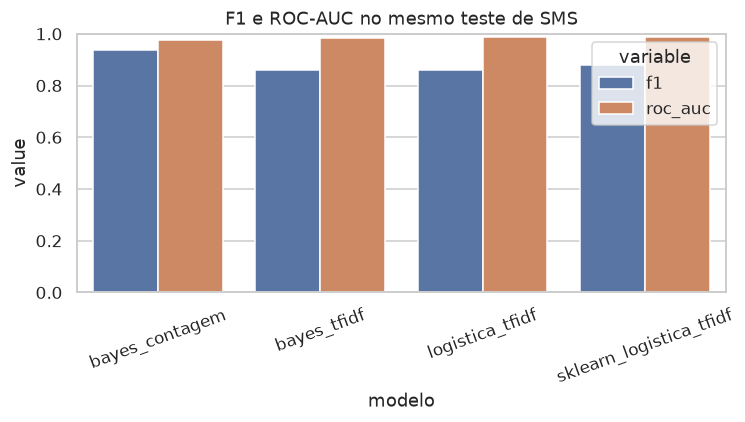

exemplos em que Bayes de contagem e logistica discordam
- y 1 bayes 1 logistica 0 3. You have received your mobile content. Enjoy
- y 1 bayes 1 logistica 0 Customer service announcement. We recently tried to make a delivery to you but were unable to do so, please call 07099833605 to re-schedule.
- y 1 bayes 1 logistica 0 You will be receiving this week's Triple Echo ringtone shortly. Enjoy it!
- y 1 bayes 1 logistica 0 Dear Voucher holder Have your next meal on us. Use the following link on your pc 2 enjoy a 2 4 1 dining experiencehttp://www.vouch4me.com/et
- y 1 bayes 1 logistica 0 As a registered optin subscriber ur draw 4 £100 gift voucher will be entered on receipt of a correct ans to 80062 Whats No1 in the BBC chart
acuracia 0.984 | baseline da classe majoritaria 0.866
precisao 0.977 | revocacao 0.904 | f1 0.939 | roc_auc 0.974
RESUMO_METRICAS {"modelo": "bayes_contagem_sms", "acuracia": 0.9842180774748924, "precisao": 0.976878612716763, "revocacao": 0.9037433155080213, "f1": 0.93

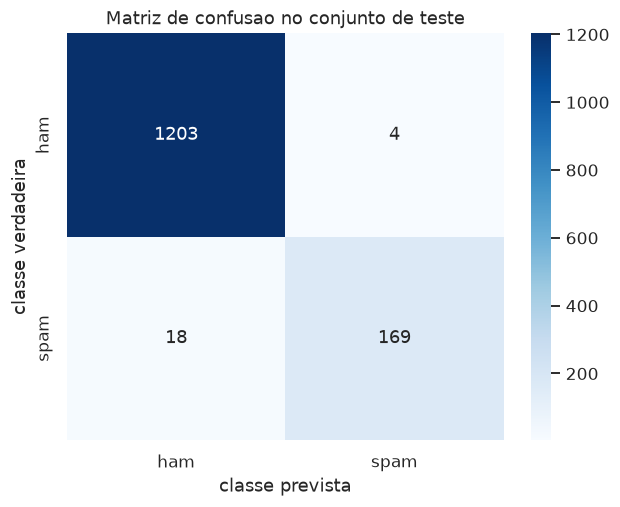

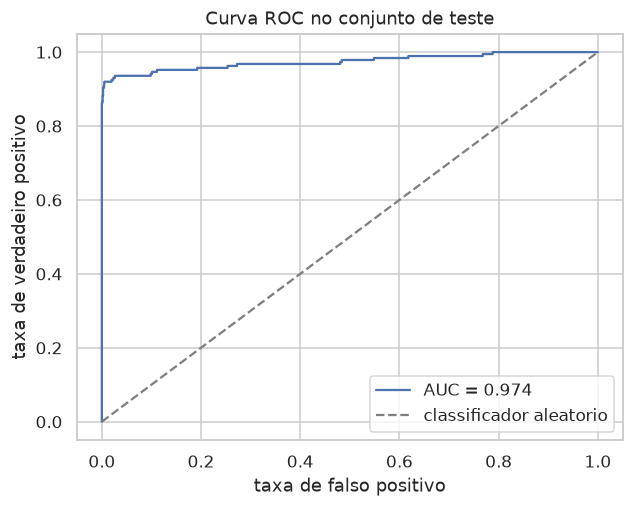

acuracia 0.967 | baseline da classe majoritaria 0.866
precisao 0.993 | revocacao 0.759 | f1 0.861 | roc_auc 0.986
RESUMO_METRICAS {"modelo": "logistica_tfidf_sms", "acuracia": 0.9670014347202296, "precisao": 0.993006993006993, "revocacao": 0.7593582887700535, "f1": 0.8606060606060606, "roc_auc": 0.9864249985600929, "baseline_majoritaria": 0.8658536585365854}


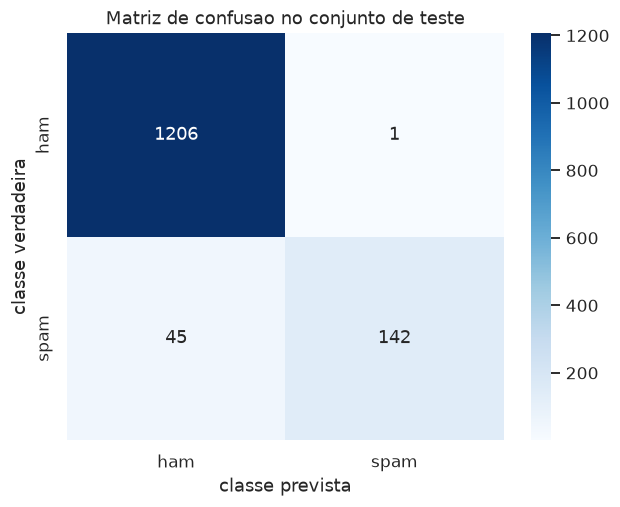

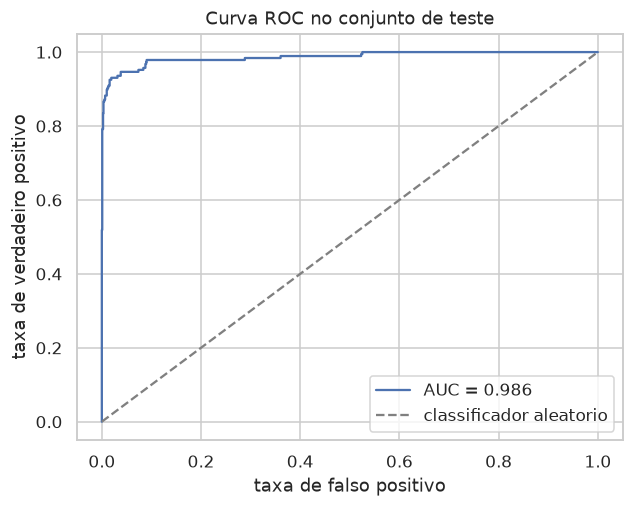

In [5]:
from mlalgos.metrics import f1_score, precision_score, recall_score, roc_auc_score

def linha(nome, y_pred, y_escore):
    return {
        "modelo": nome,
        "acuracia": float(np.mean(y_pred == y_teste)),
        "precisao": precision_score(y_teste, y_pred, pos_label=1),
        "revocacao": recall_score(y_teste, y_pred, pos_label=1),
        "f1": f1_score(y_teste, y_pred, pos_label=1),
        "roc_auc": roc_auc_score(y_teste, y_escore, pos_label=1),
    }

tabela = pd.DataFrame([
    linha("bayes_contagem", nb_contagem.predict(C_te), nb_contagem.predict_proba(C_te)[:, 1]),
    linha("bayes_tfidf", nb_tfidf.predict(T_te), nb_tfidf.predict_proba(T_te)[:, 1]),
    linha("logistica_tfidf", logistica.predict(T_te), logistica.predict_proba(T_te)[:, 1]),
    linha("sklearn_logistica_tfidf", sk_lr.predict(T_te), sk_lr.predict_proba(T_te)[:, 1]),
])
print(tabela.to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=tabela.melt(id_vars="modelo", value_vars=["f1", "roc_auc"]), x="modelo", y="value", hue="variable", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("F1 e ROC-AUC no mesmo teste de SMS")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# Onde os dois modelos do zero discordam.
pred_nb = nb_contagem.predict(C_te)
pred_lr = logistica.predict(T_te)
discorda = np.where(pred_nb != pred_lr)[0][:5]
print("exemplos em que Bayes de contagem e logistica discordam")
for i in discorda:
    print("-", "y", int(y_teste[i]), "bayes", int(pred_nb[i]), "logistica", int(pred_lr[i]), X_teste_txt[i][:140])

from mlalgos.metrics import confusion_matrix, curva_roc, f1_score, precision_score, recall_score, roc_auc_score

y_previsto = nb_contagem.predict(C_te)
y_escore = nb_contagem.predict_proba(C_te)[:, 1]
acuracia = float(np.mean(y_previsto == y_teste))
precisao = precision_score(y_teste, y_previsto, pos_label=1)
revocacao = recall_score(y_teste, y_previsto, pos_label=1)
f1 = f1_score(y_teste, y_previsto, pos_label=1)
auc = roc_auc_score(y_teste, y_escore, pos_label=1)
baseline = float(max(np.mean(y_teste == 1), np.mean(y_teste == 0)))
print(f"acuracia {acuracia:.3f} | baseline da classe majoritaria {baseline:.3f}")
print(f"precisao {precisao:.3f} | revocacao {revocacao:.3f} | f1 {f1:.3f} | roc_auc {auc:.3f}")
print("RESUMO_METRICAS " + json.dumps({
    "modelo": 'bayes_contagem_sms',
    "acuracia": acuracia,
    "precisao": precisao,
    "revocacao": revocacao,
    "f1": f1,
    "roc_auc": auc,
    "baseline_majoritaria": baseline,
}))

cm = confusion_matrix(y_teste, y_previsto, labels=[0, 1])
fig, ax = plt.subplots()
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'], ax=ax,
)
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe verdadeira")
ax.set_title("Matriz de confusao no conjunto de teste")
plt.show()

fpr, tpr, _ = curva_roc(y_teste, y_escore, pos_label=1)
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="classificador aleatorio")
ax.set_xlabel("taxa de falso positivo")
ax.set_ylabel("taxa de verdadeiro positivo")
ax.set_title("Curva ROC no conjunto de teste")
ax.legend()
plt.show()

from mlalgos.metrics import confusion_matrix, curva_roc, f1_score, precision_score, recall_score, roc_auc_score

y_previsto = logistica.predict(T_te)
y_escore = logistica.predict_proba(T_te)[:, 1]
acuracia = float(np.mean(y_previsto == y_teste))
precisao = precision_score(y_teste, y_previsto, pos_label=1)
revocacao = recall_score(y_teste, y_previsto, pos_label=1)
f1 = f1_score(y_teste, y_previsto, pos_label=1)
auc = roc_auc_score(y_teste, y_escore, pos_label=1)
baseline = float(max(np.mean(y_teste == 1), np.mean(y_teste == 0)))
print(f"acuracia {acuracia:.3f} | baseline da classe majoritaria {baseline:.3f}")
print(f"precisao {precisao:.3f} | revocacao {revocacao:.3f} | f1 {f1:.3f} | roc_auc {auc:.3f}")
print("RESUMO_METRICAS " + json.dumps({
    "modelo": 'logistica_tfidf_sms',
    "acuracia": acuracia,
    "precisao": precisao,
    "revocacao": revocacao,
    "f1": f1,
    "roc_auc": auc,
    "baseline_majoritaria": baseline,
}))

cm = confusion_matrix(y_teste, y_previsto, labels=[0, 1])
fig, ax = plt.subplots()
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'], ax=ax,
)
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe verdadeira")
ax.set_title("Matriz de confusao no conjunto de teste")
plt.show()

fpr, tpr, _ = curva_roc(y_teste, y_escore, pos_label=1)
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="classificador aleatorio")
ax.set_xlabel("taxa de falso positivo")
ax.set_ylabel("taxa de verdadeiro positivo")
ax.set_title("Curva ROC no conjunto de teste")
ax.legend()
plt.show()


## 7) Desafios

1. Por que o Bayes em TF-IDF pode perder F1 mesmo com AUC parecida? Olhe o histograma de escores.
2. Escreva uma mensagem com "free" e outra com "free" negado por uma frase longa de ham. Qual modelo troca de classe primeiro?
3. Reduza o passo da logistica para 1 e pare em 50 iteracoes. A AUC cai junto com o F1, ou so o F1?
